<a href="https://colab.research.google.com/github/ReNZzyi/IT-and-Programming/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 9. Объектно-ориентированное программирование

ФИО студента: **Петров Данила Максимович**

Группа студента: **ИНБ-б-о-26-2**

Вариант: **14**

## Задание

**Вариант 14.** Класс «Матрица MxN». Реализовать:
* инициализацию элементов матрицы случайными числами;
* вывод транспонированной матрицы;
* нахождение среднего арифметического всех элементов;
* вывод информации об объекте.

## Решение

Решение задачи состоит из следующих этапов:

1.   проектирование класса;
2.   объявление класса (кодирование);
3.   демонстрация использования класса (создание объекта и вызов методов).

На рисунке показана диаграмма спроектированного класса `Matrix`.

<figure>
<center>

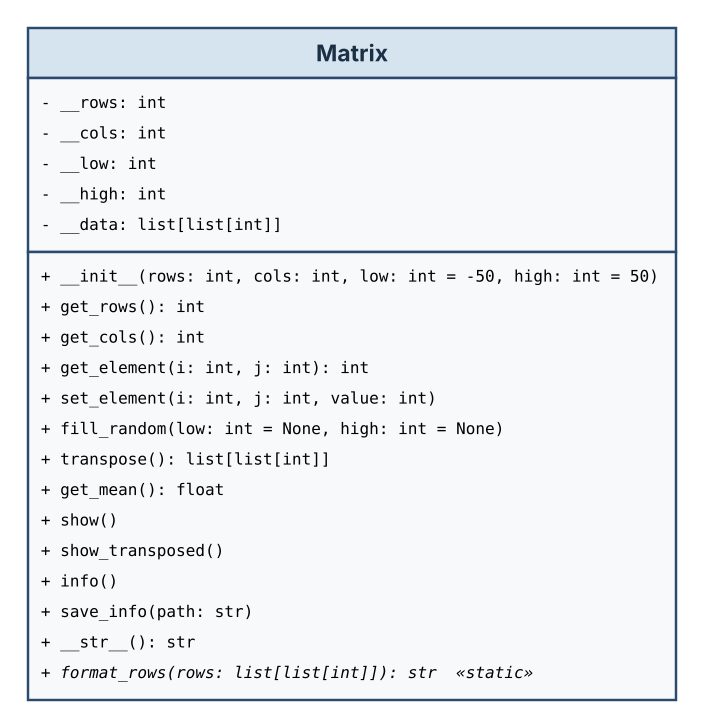

<figcaption>Диаграмма класса Matrix</figcaption></center>
</figure>

Проект класса учитывает все данные и методы, которые можно выявить, проанализировав задание:

1) закрытые поля (имена начинаются с `__`):
* `__rows`, `__cols` - количество строк M и столбцов N;
* `__low`, `__high` - диапазон случайных чисел;
* `__data` - элементы матрицы (список списков);

2) открытые методы:
* `__init__()` - конструктор: проверяет размеры и сразу заполняет матрицу случайными числами;
* `get_rows()`, `get_cols()`, `get_element()` - методы-получатели;
* `set_element()` - метод-мутатор (изменяет один элемент с проверкой индексов);
* `fill_random()` - (пере)инициализация элементов случайными целыми числами;
* `transpose()` - возвращает транспонированную матрицу (N x M), исходная не меняется;
* `get_mean()` - среднее арифметическое всех элементов;
* `show()`, `show_transposed()` - вывод исходной и транспонированной матрицы;
* `info()` - вывод полной информации об объекте;
* `save_info()` - запись информации об объекте в выходной файл;
* `__str__()` - строковое представление объекта (используется функциями `print()` и `str()`);
* `format_rows()` - статический метод: превращает любой список списков в выровненную таблицу. Он не использует данные конкретного объекта, поэтому не требует `self`.

На данном этапе проектирование завершается. Переходим к объявлению класса `Matrix`.

In [1]:
import random


class Matrix:
    def __init__(self, rows, cols, low=-50, high=50):
        if not isinstance(rows, int) or not isinstance(cols, int):
            raise TypeError('Размеры матрицы должны быть целыми числами')
        if rows <= 0 or cols <= 0:
            raise ValueError('Размеры матрицы должны быть больше нуля')
        if low > high:
            raise ValueError('Нижняя граница диапазона больше верхней')
        self.__rows = rows
        self.__cols = cols
        self.__low = low
        self.__high = high
        self.__data = []
        self.fill_random()

    def get_rows(self):
        return self.__rows

    def get_cols(self):
        return self.__cols

    def get_element(self, i, j):
        self.__check_index(i, j)
        return self.__data[i][j]

    def set_element(self, i, j, value):
        self.__check_index(i, j)
        self.__data[i][j] = value

    def __check_index(self, i, j):
        if not (0 <= i < self.__rows and 0 <= j < self.__cols):
            raise IndexError(f'Индекс ({i}, {j}) вне матрицы '
                             f'{self.__rows}x{self.__cols}')

    def fill_random(self, low=None, high=None):
        if low is not None:
            self.__low = low
        if high is not None:
            self.__high = high
        if self.__low > self.__high:
            raise ValueError('Нижняя граница диапазона больше верхней')
        self.__data = [
            [random.randint(self.__low, self.__high) for _ in range(self.__cols)]
            for _ in range(self.__rows)
        ]

    def transpose(self):
        return [
            [self.__data[i][j] for i in range(self.__rows)]
            for j in range(self.__cols)
        ]

    def get_mean(self):
        total = sum(sum(row) for row in self.__data)
        return total / (self.__rows * self.__cols)

    @staticmethod
    def format_rows(rows):
        width = max(len(str(value)) for row in rows for value in row)
        return '\n'.join(
            ' '.join(f'{value:>{width}}' for value in row) for row in rows
        )

    def show(self):
        print(f'Исходная матрица {self.__rows}x{self.__cols}:')
        print(Matrix.format_rows(self.__data))

    def show_transposed(self):
        print(f'Транспонированная матрица {self.__cols}x{self.__rows}:')
        print(Matrix.format_rows(self.transpose()))

    def __str__(self):
        return (f'Matrix {self.__rows}x{self.__cols}, '
                f'элементы из [{self.__low}; {self.__high}], '
                f'среднее = {self.get_mean():.3f}')

    def __info_text(self):
        line = '*' * 40
        return '\n'.join([
            line,
            'Матрица MxN',
            f'Размер: {self.__rows} x {self.__cols} '
            f'({self.__rows * self.__cols} элементов)',
            f'Диапазон случайных чисел: [{self.__low}; {self.__high}]',
            f'Исходная матрица:\n{Matrix.format_rows(self.__data)}',
            f'Транспонированная матрица:\n{Matrix.format_rows(self.transpose())}',
            f'Среднее арифметическое элементов: {self.get_mean():.3f}',
            line,
        ])

    def info(self):
        print(self.__info_text())

    def save_info(self, path):
        with open(path, 'w', encoding='utf-8') as f:
            f.write(self.__info_text() + '\n')

В листинге объявлен тип данных `Matrix`. Все поля закрытые: двойное подчёркивание в начале имени включает механизм *name mangling* - внутри класса поле доступно как `self.__data`, а снаружи обратиться к нему по имени `__data` нельзя. Поэтому для чтения и изменения элементов предусмотрены методы `get_element()` и `set_element()`, которые дополнительно проверяют индексы.

Транспонирование реализовано через генератор списков: элемент `[i][j]` исходной матрицы становится элементом `[j][i]` результата. Метод возвращает *новую* матрицу и не портит исходную.

Использование разработанного типа данных `Matrix`

In [2]:
random.seed(14)

m1 = Matrix(3, 5)
m1.info()

****************************************
Матрица MxN
Размер: 3 x 5 (15 элементов)
Диапазон случайных чисел: [-50; 50]
Исходная матрица:
-37  28  39  46  33
 17 -19 -16  44 -18
-13  43 -41  34   7
Транспонированная матрица:
-37  17 -13
 28 -19  43
 39 -16 -41
 46  44  34
 33 -18   7
Среднее арифметическое элементов: 9.800
****************************************


Отдельные методы класса: вывод матриц и вычисление среднего

In [3]:
m1.show()
print()
m1.show_transposed()
print()
print(f'Среднее арифметическое: {m1.get_mean():.3f}')

Исходная матрица 3x5:
-37  28  39  46  33
 17 -19 -16  44 -18
-13  43 -41  34   7

Транспонированная матрица 5x3:
-37  17 -13
 28 -19  43
 39 -16 -41
 46  44  34
 33 -18   7

Среднее арифметическое: 9.800


Проверим корректность вычислений: двойное транспонирование должно вернуть исходную матрицу, а среднее совпадает с ручным подсчётом через методы-получатели

In [4]:
rows, cols = m1.get_rows(), m1.get_cols()
original = [[m1.get_element(i, j) for j in range(cols)] for i in range(rows)]

t = m1.transpose()
tt = [[t[j][i] for j in range(cols)] for i in range(rows)]
print('Двойное транспонирование = исходная матрица:', tt == original)

manual_mean = sum(sum(row) for row in original) / (rows * cols)
print('Среднее вручную:', round(manual_mean, 3), '| get_mean():', round(m1.get_mean(), 3))

Двойное транспонирование = исходная матрица: True
Среднее вручную: 9.8 | get_mean(): 9.8


Изменение элемента методом-мутатором и повторная инициализация в другом диапазоне

In [5]:
m1.set_element(0, 0, 50)
print('Элемент [0][0] после set_element:', m1.get_element(0, 0))
print(m1)

m1.fill_random(0, 9)
print(m1)
m1.show()

Элемент [0][0] после set_element: 50
Matrix 3x5, элементы из [-50; 50], среднее = 15.600
Matrix 3x5, элементы из [0; 9], среднее = 4.667
Исходная матрица 3x5:
4 7 6 6 1
4 3 5 5 4
5 8 2 2 8


Матрица другого размера (M ≠ N), сохранение информации в выходной файл

In [6]:
m2 = Matrix(4, 2, low=-10, high=10)
m2.save_info('matrix_info.txt')

print('Содержимое файла matrix_info.txt:')
print(open('matrix_info.txt', encoding='utf-8').read())

Содержимое файла matrix_info.txt:
****************************************
Матрица MxN
Размер: 4 x 2 (8 элементов)
Диапазон случайных чисел: [-10; 10]
Исходная матрица:
 -2  -5
-10  10
 -8  -7
  9   0
Транспонированная матрица:
 -2 -10  -8   9
 -5  10  -7   0
Среднее арифметическое элементов: -1.625
****************************************



Класс защищён от некорректных данных и от прямого доступа к закрытым полям

In [7]:
for args in [(0, 3), (2, 2.5), (2, 2, 10, 1)]:
    try:
        Matrix(*args)
    except (ValueError, TypeError) as e:
        print(f'Matrix{args}: {type(e).__name__}: {e}')

try:
    m2.set_element(4, 0, 1)
except IndexError as e:
    print('set_element(4, 0):', e)

try:
    print(m2.__data)
except AttributeError as e:
    print('Доступ к m2.__data:', e)

Matrix(0, 3): ValueError: Размеры матрицы должны быть больше нуля
Matrix(2, 2.5): TypeError: Размеры матрицы должны быть целыми числами
Matrix(2, 2, 10, 1): ValueError: Нижняя граница диапазона больше верхней
set_element(4, 0): Индекс (4, 0) вне матрицы 4x2
Доступ к m2.__data: 'Matrix' object has no attribute '__data'


**Вывод.** Разработан класс `Matrix` с закрытыми полями, конструктором, методами-получателями и мутатором. Класс заполняет матрицу MxN случайными числами, выводит её и транспонированную матрицу, вычисляет среднее арифметическое всех элементов и выводит (в том числе в файл) полную информацию об объекте. Корректность транспонирования и среднего проверена независимым расчётом.

# Контрольные вопросы

**1. Дайте определение понятию класс.**

Класс - это пользовательский тип данных, описывающий структуру и поведение объектов: какие у них есть данные (поля, атрибуты) и какие действия над ними можно выполнять (методы). Класс - это «чертёж», а объект (экземпляр) - конкретная сущность, созданная по этому чертежу. Например, `Matrix` - класс, а `m1` и `m2` - два его объекта со своими размерами и элементами.

**2. Продемонстрируйте использование метода `__init__`. Поясните назначение данного метода.**

`__init__` - конструктор (точнее, инициализатор). Он автоматически вызывается сразу после создания объекта и задаёт начальные значения атрибутов. Аргументы, переданные при создании объекта `Class(...)`, попадают в параметры `__init__`.

In [8]:
class Point:
    def __init__(self, x=0, y=0):
        print('Вызван __init__')
        self.x = x
        self.y = y


p = Point(3, 4)
print(p.x, p.y)

Вызван __init__
3 4


**3. Поясните назначение статических методов и их отличия от методов класса.**

* **Статический метод** (`@staticmethod`) не получает ни объект (`self`), ни класс (`cls`). Это обычная функция, логически помещённая внутрь класса. Пример - `Matrix.format_rows()`: форматирует любой список списков и не зависит от конкретной матрицы.
* **Метод класса** (`@classmethod`) первым параметром получает сам класс `cls`. Через `cls` можно обращаться к атрибутам класса и создавать новые объекты - поэтому такие методы часто используют как альтернативные конструкторы. При наследовании `cls` будет указывать на класс-наследник.

In [9]:
class Temperature:
    def __init__(self, celsius):
        self.celsius = celsius

    @staticmethod
    def c_to_f(c):
        return c * 9 / 5 + 32

    @classmethod
    def from_fahrenheit(cls, f):
        return cls((f - 32) * 5 / 9)


print(Temperature.c_to_f(100))
t = Temperature.from_fahrenheit(212)
print(type(t).__name__, t.celsius)

212.0
Temperature 100.0


**4. Для чего используется параметр `self` в каждом методе класса?**

`self` - ссылка на объект, для которого вызван метод. Вызов `m1.get_mean()` Python превращает в `Matrix.get_mean(m1)`, то есть объект `m1` передаётся первым аргументом. Через `self` метод получает доступ к атрибутам и другим методам именно этого объекта, поэтому у `m1` и `m2` одни и те же методы работают со своими данными.

**5. Сколько методов `__init__` может быть объявлено внутри класса?**

Фактически действует только один. Python не поддерживает перегрузку методов: если объявить `__init__` несколько раз, каждое следующее объявление заменит предыдущее, и работать будет последнее. Разные варианты создания объекта реализуют через параметры по умолчанию, `*args/**kwargs` или методы класса (`@classmethod`).

In [10]:
class A:
    def __init__(self):
        print('первый __init__')

    def __init__(self, x):
        print('второй __init__, x =', x)


A(1)
try:
    A()
except TypeError as e:
    print('A():', e)

второй __init__, x = 1
A(): A.__init__() missing 1 required positional argument: 'x'


**6. Каким образом в классе Python атрибут скрывается от программного кода, находящегося за пределами класса?**

Имя атрибута начинают с двух символов подчёркивания: `self.__data`. Python применяет к нему *name mangling* - переименовывает в `_Matrix__data`. Внутри класса атрибут доступен по короткому имени, а снаружи обращение `obj.__data` вызывает `AttributeError`. Одно подчёркивание (`_data`) - лишь соглашение «внутреннее, не трогать», без технической защиты. Полностью закрытых атрибутов в Python нет: искажённое имя всё ещё доступно.

In [11]:
print([name for name in vars(m2) if 'data' in name])
print(m2._Matrix__data)

['_Matrix__data']
[[-2, -5], [-10, 10], [-8, -7], [9, 0]]


**7. Какова задача метода `__str__()`?**

`__str__()` возвращает удобочитаемое строковое представление объекта. Без него `print(obj)` выводит малоинформативное `<__main__.Matrix object at 0x...>`.

**8. Каким образом происходит вызов метода `__str__()`?**

Напрямую его обычно не вызывают. Он вызывается автоматически, когда объект нужно преобразовать в строку: в `print(obj)`, `str(obj)`, f-строках `f'{obj}'` и при `format()`.

In [12]:
print(m2)
s = str(m2)
print(f'Объект: {m2}')

Matrix 4x2, элементы из [-10; 10], среднее = -1.625
Объект: Matrix 4x2, элементы из [-10; 10], среднее = -1.625


**9. Что такое атрибут экземпляра?**

Атрибут экземпляра - переменная, принадлежащая конкретному объекту. Обычно создаётся в методах через `self.имя = значение` (как правило, в `__init__`). У каждого объекта свой набор значений: изменение атрибута одного объекта не затрагивает другие. Этим он отличается от *атрибута класса*, который объявлен в теле класса и общий для всех экземпляров.

In [13]:
class Counter:
    created = 0

    def __init__(self, name):
        self.name = name
        Counter.created += 1


c1, c2 = Counter('first'), Counter('second')
print(c1.name, c2.name, '| создано объектов:', Counter.created)

first second | создано объектов: 2


**10. Что такое метод-получатель? Что такое метод-мутатор?**

* **Метод-получатель** (getter, accessor) возвращает значение атрибута, не изменяя его. В классе `Matrix` это `get_rows()`, `get_cols()`, `get_element()`.
* **Метод-мутатор** (setter) изменяет значение атрибута. Обычно он проверяет новое значение, чтобы объект не оказался в некорректном состоянии. В классе `Matrix` это `set_element()`: он не позволяет записать значение за пределы матрицы.

Такие методы - основа инкапсуляции: доступ к закрытым данным идёт только через контролируемый интерфейс. В Python то же самое часто оформляют через декоратор `@property`.

In [14]:
m3 = Matrix(2, 2, 1, 5)
print('Получатель:', m3.get_element(1, 1))
m3.set_element(1, 1, 42)
print('После мутатора:', m3.get_element(1, 1))

Получатель: 2
После мутатора: 42
